In [ ]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

RANDOM_STATE = 42

In [ ]:
uploaded = files.upload()
uploaded_names = list(uploaded.keys())
print("Uploaded files:", uploaded_names)

def load_news_files(file_names):
    lower_names = {name.lower(): name for name in file_names}

    # Option B: common two-file Kaggle format
    fake_name = next((original for low, original in lower_names.items()
                      if low == "fake.csv" or "fake" in low), None)
    true_name = next((original for low, original in lower_names.items()
                      if low == "true.csv" or "true" in low or "real" in low), None)

    if fake_name and true_name and fake_name != true_name:
        fake_df = pd.read_csv(fake_name)
        real_df = pd.read_csv(true_name)
        fake_df["label"] = "FAKE"
        real_df["label"] = "REAL"
        return pd.concat([fake_df, real_df], ignore_index=True)

    # Option A: one combined CSV
    csv_names = [n for n in file_names if n.lower().endswith(".csv")]
    if len(csv_names) == 1:
        return pd.read_csv(csv_names[0])

    raise ValueError(
        "Please upload either one combined CSV with text and label columns, "
        "or two files such as Fake.csv and True.csv."
    )

df = load_news_files(uploaded_names)
print("Dataset shape:", df.shape)
display(df.head())
print("Columns:", list(df.columns))

Saving Fake.csv to Fake.csv
Saving True.csv to True.csv
Uploaded files: ['Fake.csv', 'True.csv']
Dataset shape: (44898, 5)


,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",FAKE
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",FAKE
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",FAKE
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",FAKE
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",FAKE


Columns: ['title', 'text', 'subject', 'date', 'label']


In [ ]:
def find_column(columns, candidates):
    lookup = {str(c).strip().lower(): c for c in columns}
    for candidate in candidates:
        if candidate in lookup:
            return lookup[candidate]
    return None

TEXT_COLUMN = find_column(
    df.columns, ["text", "news", "content", "article", "statement", "title"]
)
LABEL_COLUMN = find_column(
    df.columns, ["label", "class", "target", "category", "is_fake"]
)

# If automatic detection fails, replace None with the exact column name.
# Example:
# TEXT_COLUMN = "text"
# LABEL_COLUMN = "label"

if TEXT_COLUMN is None or LABEL_COLUMN is None:
    raise ValueError(
        "Could not identify text/label columns. Set TEXT_COLUMN and "
        "LABEL_COLUMN manually using the column names printed above."
    )

print("Text column:", TEXT_COLUMN)
print("Label column:", LABEL_COLUMN)

Text column: text
Label column: label


In [ ]:
data = df[[TEXT_COLUMN, LABEL_COLUMN]].copy()
data.columns = ["text", "label"]
data = data.dropna()
data["text"] = data["text"].astype(str)
data["label"] = data["label"].astype(str).str.strip().str.upper()

def clean_text(text):
    text = text.lower()
    text = re.sub(r"<.*?>", " ", text)          # remove HTML tags
    text = re.sub(r"http\S+|www\S+", " ", text) # remove URLs
    text = re.sub(r"[^a-zA-Z\s]", " ", text)   # keep English letters
    text = re.sub(r"\s+", " ", text).strip()   # normalize spaces
    return text

data["clean_text"] = data["text"].apply(clean_text)
data = data[data["clean_text"].str.len() > 0]

# Map common text labels to consistent names.
label_map = {
    "FAKE": "FAKE", "FALSE": "FAKE", "0": "FAKE",
    "REAL": "REAL", "TRUE": "REAL", "1": "REAL"
}
data["label"] = data["label"].map(lambda x: label_map.get(x, x))

if set(data["label"].unique()) != {"FAKE", "REAL"}:
    raise ValueError(
        "Expected two classes labelled FAKE/REAL (or FALSE/TRUE, or 0/1). "
        f"Found: {sorted(data['label'].unique())}. Edit label_map if needed."
    )

data = data.drop_duplicates(subset=["clean_text"])
print("Cleaned dataset shape:", data.shape)
print("\nClass distribution:")
display(data["label"].value_counts().to_frame("article_count"))
display(data[["clean_text", "label"]].head())

Cleaned dataset shape: (38313, 3)

Class distribution:


,article_count
label,
REAL,20921
FAKE,17392


,clean_text,label
0,donald trump just couldn t wish all americans ...,FAKE
1,house intelligence committee chairman devin nu...,FAKE
2,on friday it was revealed that former milwauke...,FAKE
3,on christmas day donald trump announced that h...,FAKE
4,pope francis used his annual christmas day mes...,FAKE


In [ ]:
X = data["clean_text"]
y = data["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training articles:", len(X_train))
print("Testing articles:", len(X_test))

Training articles: 26819
Testing articles: 11494


In [ ]:
models = {
    "Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(stop_words="english", max_df=0.95)),
        ("classifier", MultinomialNB())
    ]),
    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(stop_words="english", max_df=0.95)),
        ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    "SVM": Pipeline([
        ("tfidf", TfidfVectorizer(stop_words="english", max_df=0.95)),
        ("classifier", LinearSVC(random_state=RANDOM_STATE))
    ])
}

results = []
trained_models = {}

for model_name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    trained_models[model_name] = pipeline

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, pos_label="FAKE", zero_division=0),
        "Recall": recall_score(y_test, predictions, pos_label="FAKE", zero_division=0),
        "F1-score": f1_score(y_test, predictions, pos_label="FAKE", zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False)
display(results_df.style.format({
    "Accuracy": "{:.4f}",
    "Precision": "{:.4f}",
    "Recall": "{:.4f}",
    "F1-score": "{:.4f}"
}))

,Model,Accuracy,Precision,Recall,F1-score
2,SVM,0.9892,0.9915,0.9847,0.9881
1,Logistic Regression,0.9806,0.9852,0.9718,0.9785
0,Naive Bayes,0.9301,0.9532,0.8898,0.9204


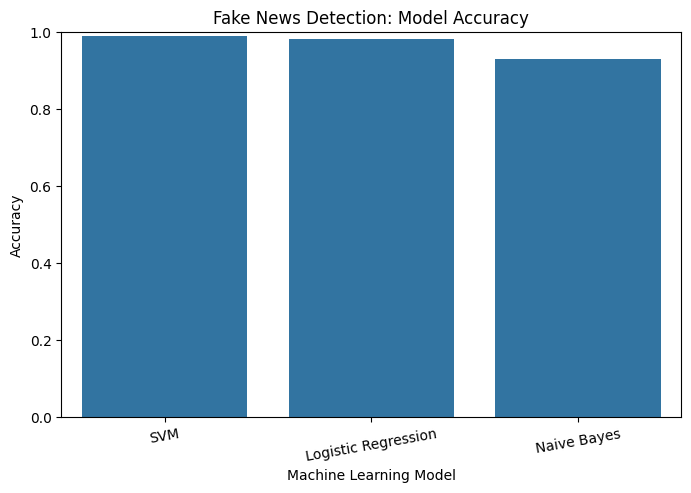

In [ ]:
plt.figure(figsize=(8, 5))
sns.barplot(data=results_df, x="Model", y="Accuracy")
plt.ylim(0, 1)
plt.title("Fake News Detection: Model Accuracy")
plt.ylabel("Accuracy")
plt.xlabel("Machine Learning Model")
plt.xticks(rotation=10)
plt.show()

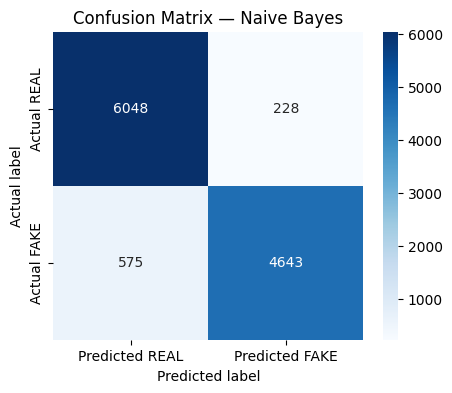

Classification report — Naive Bayes
              precision    recall  f1-score   support

        FAKE       0.95      0.89      0.92      5218
        REAL       0.91      0.96      0.94      6276

    accuracy                           0.93     11494
   macro avg       0.93      0.93      0.93     11494
weighted avg       0.93      0.93      0.93     11494



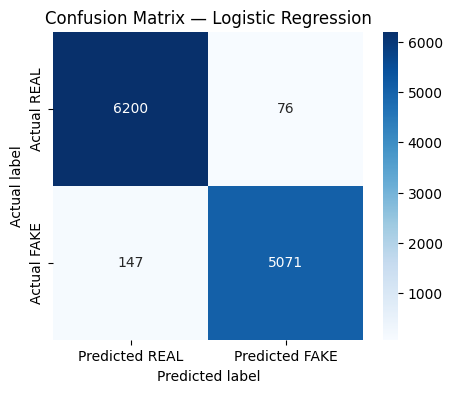

Classification report — Logistic Regression
              precision    recall  f1-score   support

        FAKE       0.99      0.97      0.98      5218
        REAL       0.98      0.99      0.98      6276

    accuracy                           0.98     11494
   macro avg       0.98      0.98      0.98     11494
weighted avg       0.98      0.98      0.98     11494



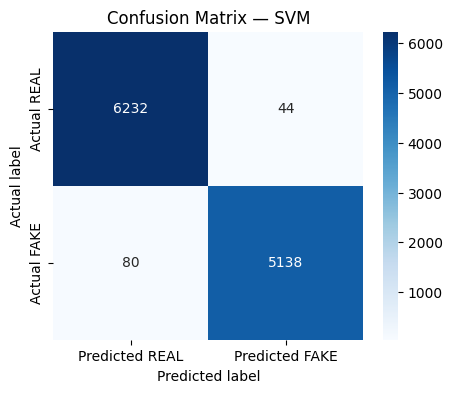

Classification report — SVM
              precision    recall  f1-score   support

        FAKE       0.99      0.98      0.99      5218
        REAL       0.99      0.99      0.99      6276

    accuracy                           0.99     11494
   macro avg       0.99      0.99      0.99     11494
weighted avg       0.99      0.99      0.99     11494



In [ ]:
for model_name, pipeline in trained_models.items():
    predictions = pipeline.predict(X_test)
    cm = confusion_matrix(y_test, predictions, labels=["REAL", "FAKE"])

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=["Predicted REAL", "Predicted FAKE"],
        yticklabels=["Actual REAL", "Actual FAKE"]
    )
    plt.title(f"Confusion Matrix — {model_name}")
    plt.ylabel("Actual label")
    plt.xlabel("Predicted label")
    plt.show()

    print(f"Classification report — {model_name}")
    print(classification_report(
        y_test, predictions, labels=["FAKE", "REAL"], zero_division=0
    ))

In [ ]:
chosen_model_name = "SVM"  # Change to "Naive Bayes" or "Logistic Regression"

news_article = input("Paste a news article: ")
cleaned_article = clean_text(news_article)

if not cleaned_article:
    print("Please enter some meaningful news text.")
else:
    prediction = trained_models[chosen_model_name].predict([cleaned_article])[0]
    print("Model:", chosen_model_name)
    print("Predicted class:", prediction)

Paste a news article: • Cyclone Murasu (Andhra Pradesh): The landfall process continues along the coast of Andhra Pradesh with no major power disruptions reported so far, while authorities monitor receding floodwaters and road damage around Chennai. Read live updates on The Hindu.
Model: SVM
Predicted class: FAKE


In [ ]:
import joblib

joblib.dump(trained_models[chosen_model_name], "fake_news_detection_model.joblib")
files.download("fake_news_detection_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>